In [1]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
cleaned_review = "text/cleaned_review.txt"
with open(cleaned_review, "r", encoding="utf-8") as file:
    lines = [line.strip() for line in file if line.strip()]
to_remove = {"no", "not", "nor"}

def text_embedding(embedding_technique, documents, features, minimum):
    vectorizer = embedding_technique(max_features=features, min_df=minimum, ngram_range=(1,2))
    sparse_vector = vectorizer.fit_transform(documents)
    df= pd.DataFrame(sparse_vector.toarray(),columns=vectorizer.get_feature_names_out())
    df = df.drop(columns=to_remove, errors="ignore")
    return(df)
features = 50
minimum = 100

BoW = text_embedding(CountVectorizer, lines, features, minimum)
tfidf = text_embedding(TfidfVectorizer, lines, features, minimum)
print("Text embedding completed, proceed with the next step")

Text embedding completed, proceed with the next step


In [2]:
BoW.head()

,also,back,battery,button,buy,cable,case,charge,charger,come,...,screen protector,still,take,thing,time,use,want,well,work,would
0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,0,0,0,1,0,0,0,0,0,1,...,1,0,0,0,1,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0


In [3]:
BoW.sum().sort_values(ascending=False)

phone               200385
case                169321
use                 116442
one                  95922
charge               92610
get                  88599
like                 80125
work                 78056
good                 75631
great                69789
would                68106
battery              67652
screen               64139
well                 62493
look                 53385
iphone               51225
fit                  50740
make                 49824
time                 49456
buy                  47295
charger              46887
product              45982
device               44203
go                   44063
come                 39419
really               38884
love                 38352
also                 37914
protector            35331
need                 34559
easy                 33282
take                 33052
price                32565
back                 32080
much                 31907
nice                 30790
little               30463
q

In [4]:
tfidf.head()


,also,back,battery,button,buy,cable,case,charge,charger,come,...,screen protector,still,take,thing,time,use,want,well,work,would
0,0.0,0.0,0.0,0.000000,0.308897,0.0,0.0,0.0,0.0,0.000000,...,0.00000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000
1,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,...,0.00000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.525421,0.000000
2,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,...,0.00000,0.0,0.0,0.0,0.000000,0.282693,0.0,0.0,0.000000,0.000000
3,0.0,0.0,0.0,0.312222,0.000000,0.0,0.0,0.0,0.0,0.256824,...,0.32286,0.0,0.0,0.0,0.243125,0.000000,0.0,0.0,0.000000,0.217516
4,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,...,0.00000,0.0,0.0,0.0,0.000000,0.430927,0.0,0.0,0.000000,0.000000


In [5]:
tfidf.sum().sort_values(ascending=False)

case                26528.021014
phone               25220.221309
use                 16177.191800
work                15223.974618
one                 14913.386872
great               14849.678621
get                 14652.209534
good                13962.741459
like                13785.450345
charge              13287.817329
well                11810.568903
love                11710.124835
fit                 11522.987133
would               11511.735457
buy                 11186.509943
screen              10972.423189
look                10749.693582
battery             10307.977347
product             10279.428148
iphone               9560.185495
time                 8977.484402
make                 8855.240685
charger              8629.979469
price                8554.801937
really               8246.701167
come                 7839.577817
go                   7776.937774
easy                 7579.485327
nice                 7526.070508
need                 7009.073688
recommend 

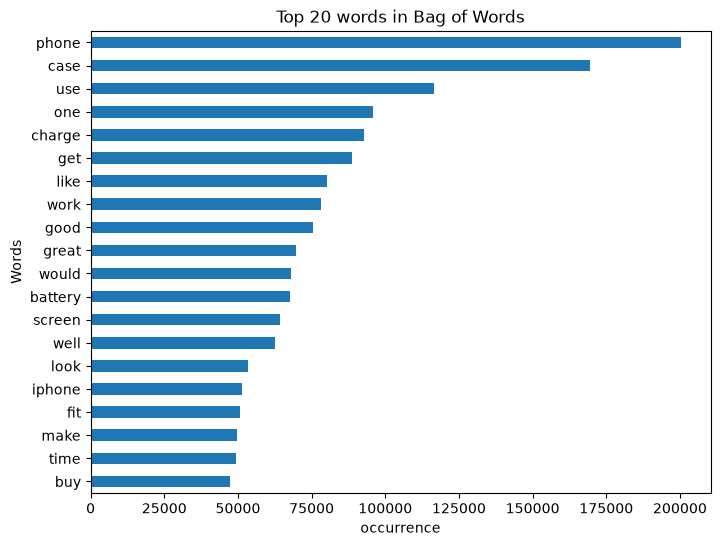

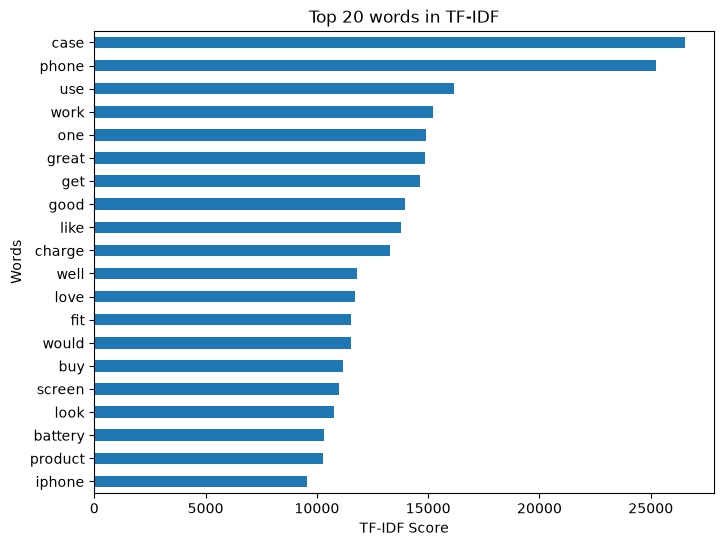

In [8]:
# plotting a graph
import matplotlib.pyplot as plt

def plot_chart_top_words(df,title,xlabel, ylabel, n_top_words):
    top_words = df.sum().sort_values(ascending=False).head(n_top_words)
    plt.figure(figsize=(8, 6))
    top_words.sort_values().plot(kind="barh")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.show()
n_top_words = 20

plot_chart_top_words(BoW, "Top " + str(n_top_words) + " words in Bag of Words", "occurrence", "Words", n_top_words )
plot_chart_top_words(tfidf, "Top " + str(n_top_words) + " words in TF-IDF", "TF-IDF Score", "Words", n_top_words )